# 01 · Data exploration — Oxford-IIIT Pet

The model trains on **all pets** (cats + dogs) and is evaluated on **cats**.
Each image has a *trimap*: `1 = pet`, `2 = background`, `3 = pet border`.
The binary target is pet + border vs background.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from manet_lib import read_pet_list, split_train_val, PetSegDataset, denormalize, overlay, mask_outline

ROOT = Path("data/oxford-iiit-pet")
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
SEED = 42

In [2]:
trainval = read_pet_list(ROOT, "trainval")
test = read_pet_list(ROOT, "test")
train_rows, val_rows = split_train_val(trainval, val_frac=0.15, seed=SEED)

df = pd.concat([
    pd.DataFrame(train_rows).assign(split="train"),
    pd.DataFrame(val_rows).assign(split="val"),
    pd.DataFrame(test).assign(split="test"),
])
counts = df.pivot_table(index="split", columns="species", values="name", aggfunc="count").loc[["train", "val", "test"]]
counts["total"] = counts.sum(axis=1)
counts

species,cat,dog,total
split,,,
train,1010,2119,3129
val,178,373,551
test,1183,2486,3669


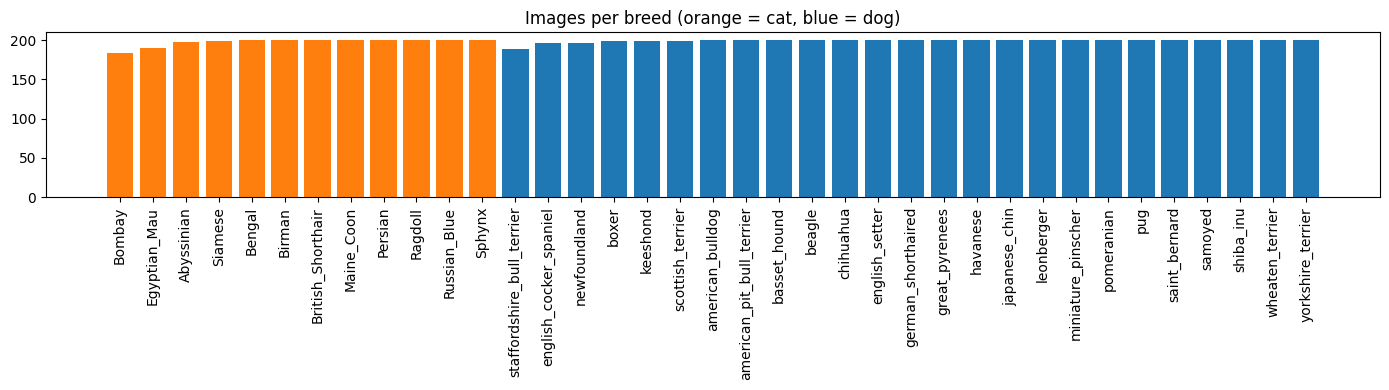

In [3]:
breed_counts = df.groupby(["breed", "species"]).size().reset_index(name="n").sort_values(["species", "n"])
fig, ax = plt.subplots(figsize=(14, 4))
colors = breed_counts["species"].map({"cat": "tab:orange", "dog": "tab:blue"})
ax.bar(breed_counts["breed"], breed_counts["n"], color=colors)
ax.set_title("Images per breed (orange = cat, blue = dog)")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()

## Example images, trimaps and the binary target

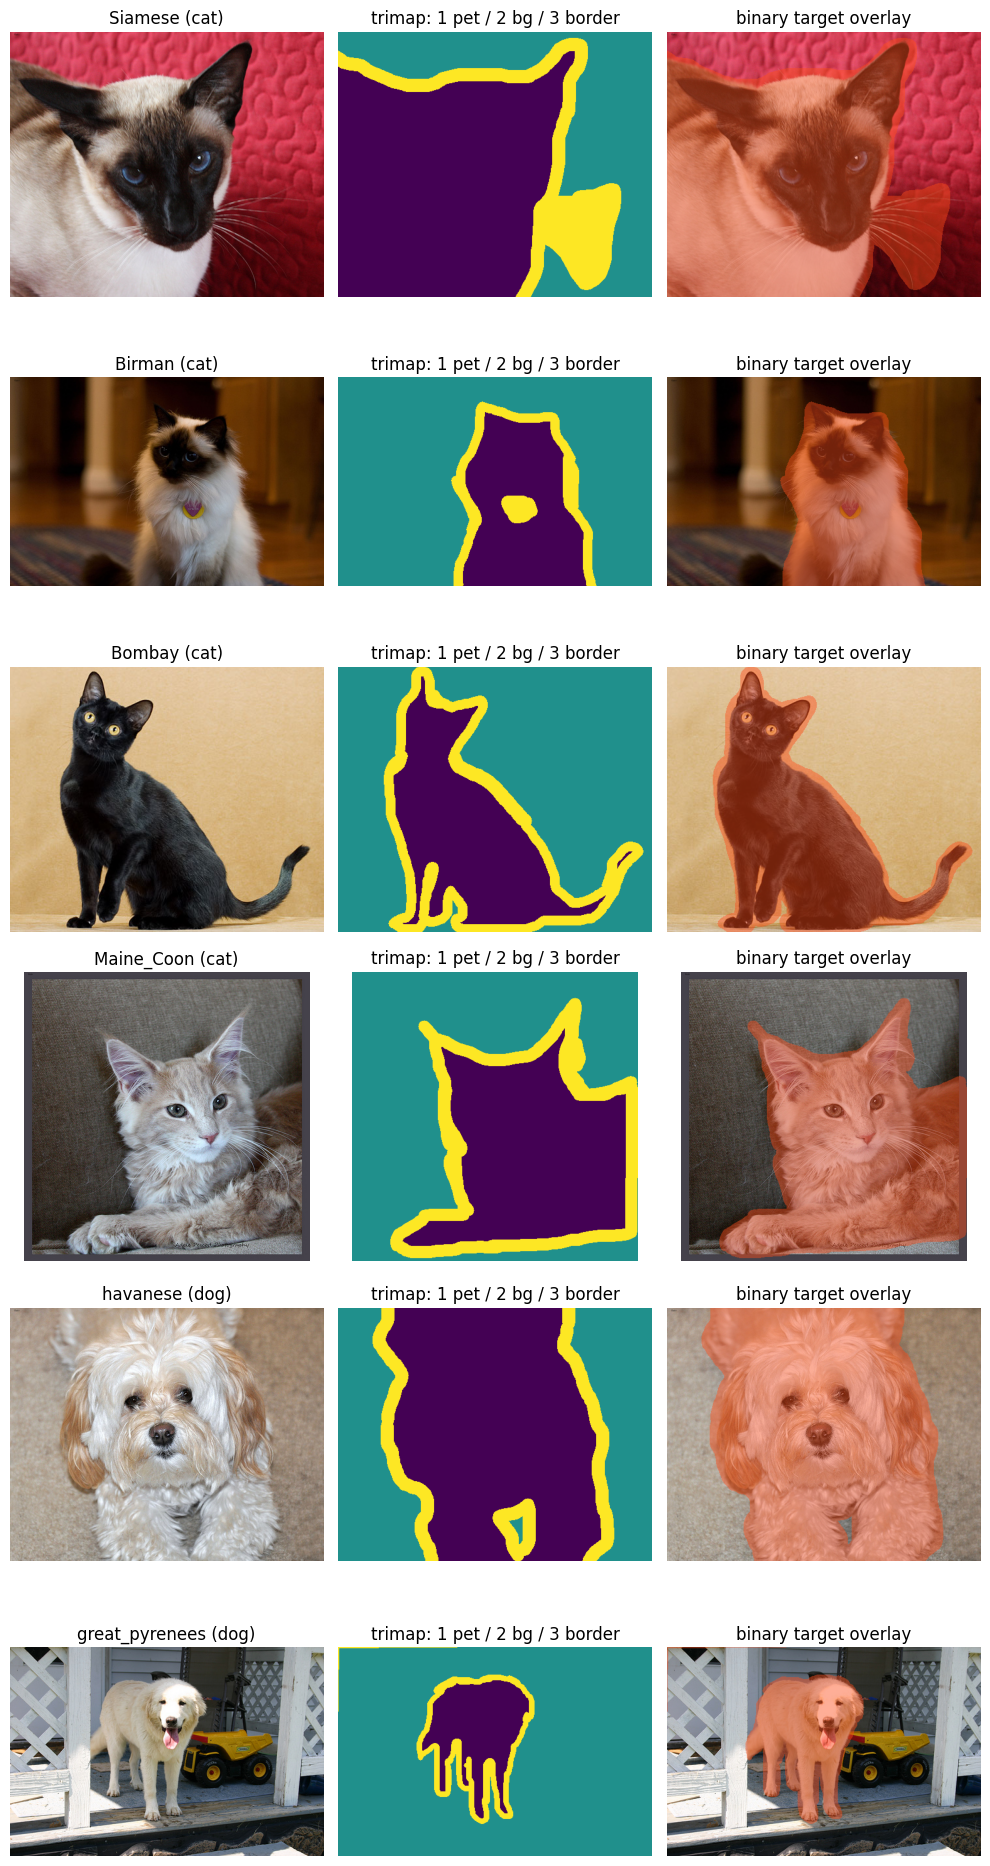

In [4]:
rng = np.random.default_rng(SEED)
cats = [r for r in trainval if r["species"] == "cat"]
dogs = [r for r in trainval if r["species"] == "dog"]
examples = [cats[i] for i in rng.choice(len(cats), 4, replace=False)] + [dogs[i] for i in rng.choice(len(dogs), 2, replace=False)]

fig, axes = plt.subplots(len(examples), 3, figsize=(10, 3.2 * len(examples)))
for row, r in zip(axes, examples):
    img = Image.open(ROOT / "images" / f"{r['name']}.jpg").convert("RGB")
    tri = np.array(Image.open(ROOT / "annotations" / "trimaps" / f"{r['name']}.png"))
    target = tri != 2
    row[0].imshow(img); row[0].set_title(f"{r['breed']} ({r['species']})")
    row[1].imshow(tri, cmap="viridis", vmin=1, vmax=3); row[1].set_title("trimap: 1 pet / 2 bg / 3 border")
    row[2].imshow(overlay(np.asarray(img) / 255.0, target)); row[2].set_title("binary target overlay")
    for a in row: a.axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "01_examples.png", dpi=110); plt.show()

## How much of each image is pet?

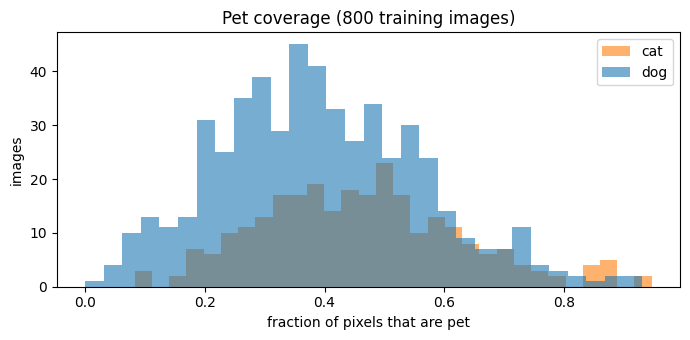

,count,mean,std,min,25%,50%,75%,max
species,,,,,,,,
cat,269.0,0.461736,0.169105,0.08264,0.338364,0.451296,0.570330,0.946807
dog,531.0,0.392269,0.170249,0.00000,0.271389,0.383337,0.503524,0.930390


In [5]:
def pet_fraction(name):
    tri = np.array(Image.open(ROOT / "annotations" / "trimaps" / f"{name}.png"))
    return float((tri != 2).mean())

sample = df[df.split == "train"].sample(800, random_state=SEED).copy()
sample["pet_frac"] = sample["name"].map(pet_fraction)
fig, ax = plt.subplots(figsize=(7, 3.5))
for sp, c in [("cat", "tab:orange"), ("dog", "tab:blue")]:
    ax.hist(sample.loc[sample.species == sp, "pet_frac"], bins=30, alpha=0.6, label=sp, color=c)
ax.set_xlabel("fraction of pixels that are pet"); ax.set_ylabel("images"); ax.legend()
ax.set_title("Pet coverage (800 training images)")
plt.tight_layout(); plt.show()
sample.groupby("species")["pet_frac"].describe()

## Training augmentation preview
Random resized crop, horizontal flip, small rotation and color jitter. The mask (outline in red) moves with the image.

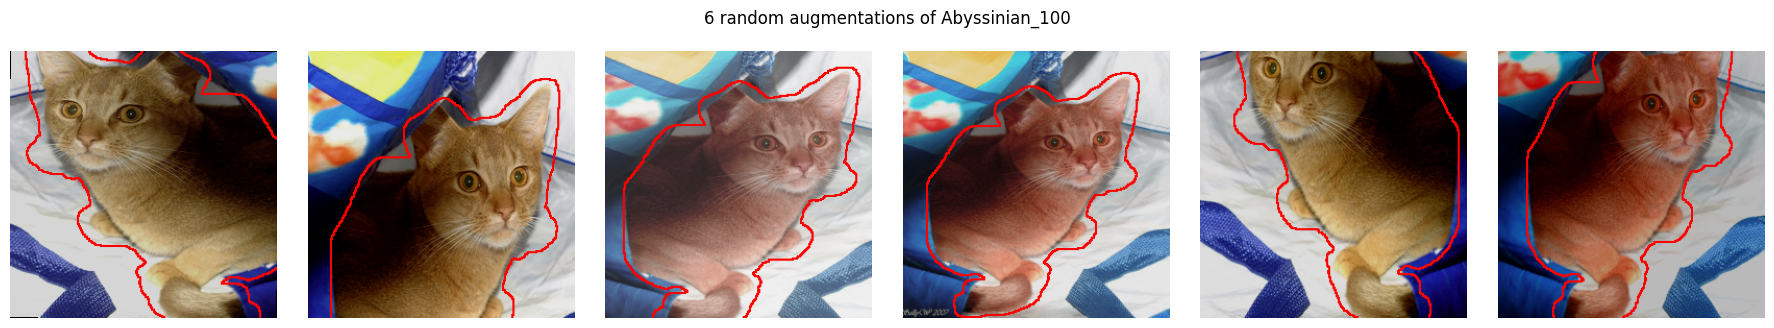

In [6]:
aug_ds = PetSegDataset(ROOT, [cats[0]], img_size=256, train=True)
fig, axes = plt.subplots(1, 6, figsize=(18, 3.3))
for ax in axes:
    x, y, meta = aug_ds[0]
    img = denormalize(x)
    img[mask_outline(y[0].numpy(), width=1)] = (1, 0, 0)
    ax.imshow(img); ax.axis("off")
fig.suptitle(f"6 random augmentations of {cats[0]['name']}")
plt.tight_layout(); plt.show()